In [6]:
import os
import pandas as pd
import seaborn as sns

In [7]:
tx_mapping_df = pd.read_csv(r'\\allen\programs\celltypes\workgroups\mousecelltypes\SarahWB\datasets\human_exc\analysis\20240911_seaad\MET_typing\config\tx_mapping_file.csv', index_col = 'cell_id')
tx_mapping_df

,Lamp5_Lhx6_1,Lamp5_1,Lamp5_2,Lamp5_3,Lamp5_4,Lamp5_5,Lamp5_6,Pax6_1,Pax6_2,Pax6_3,...,L6b_5,L6b_6,L6 IT Car3_1,L6 IT Car3_2,L6 IT Car3_3,L5/6 NP_1,L5/6 NP_2,L5/6 NP_3,L5/6 NP_6,L5/6 NP_4
cell_id,,,,,,,,,,,,,,,,,,,,,
616836450,0.00,0.00,0.00,0.00,0.00,0.0,0.02,0.00,0.00,0.00,...,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.00,0.0
616840597,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.00,0.0
616858807,0.30,0.00,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.02,...,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.00,0.0
636982263,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.00,0.0
636986380,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00,...,0.11,0.01,0.04,0.0,0.15,0.00,0.00,0.00,0.00,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1371191464,0.03,0.22,0.04,0.06,0.00,0.0,0.00,0.02,0.01,0.02,...,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.00,0.0
1371195226,0.00,0.03,0.00,0.00,0.00,0.0,0.00,0.00,0.11,0.00,...,0.00,0.00,0.00,0.0,0.00,0.03,0.19,0.18,0.16,0.0
1371210352,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.00,0.0


In [15]:
tx_mapping_df.sum(axis=1)

cell_id
616836450     1.0
616840597     1.0
616858807     1.0
636982263     1.0
636986380     1.0
             ... 
1371191464    1.0
1371195226    1.0
1371210352    1.0
1371179407    1.0
1371210977    1.0
Length: 7444, dtype: float64

<Axes: ylabel='cell_id'>

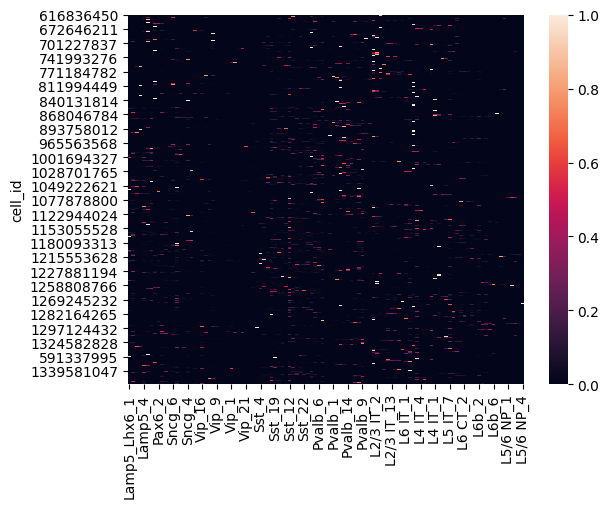

In [8]:
sns.heatmap(tx_mapping_df)

<Axes: ylabel='cell_id'>

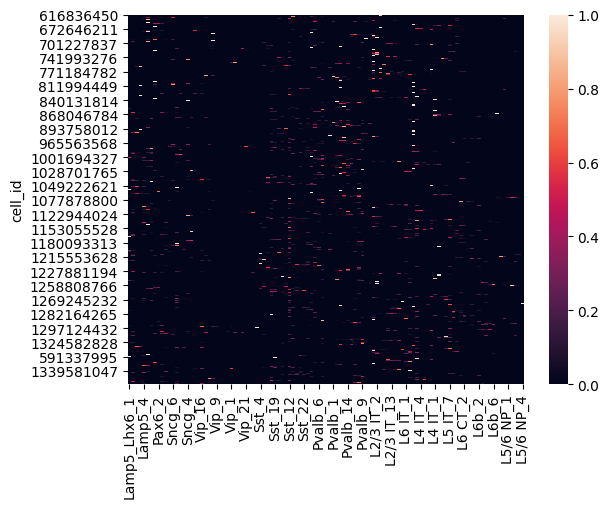

In [9]:
# Keep only the top four values per row, set others to 0
tx_mapping_top_four_df = tx_mapping_df.apply(lambda row: row.where(row >= row.nlargest(4).min(), 0), axis=1)
sns.heatmap(tx_mapping_top_four_df)

In [14]:
#row sums
tx_mapping_top_four_df.sum(axis=1)

cell_id
616836450     0.65
616840597     0.95
616858807     0.81
636982263     1.00
636986380     0.77
              ... 
1371191464    0.65
1371195226    0.65
1371210352    0.97
1371179407    0.70
1371210977    0.76
Length: 7444, dtype: float64

In [10]:
#look at the difference between these two to make sure stuff was changed. 
difference_df = tx_mapping_df-tx_mapping_top_four_df

<Axes: ylabel='cell_id'>

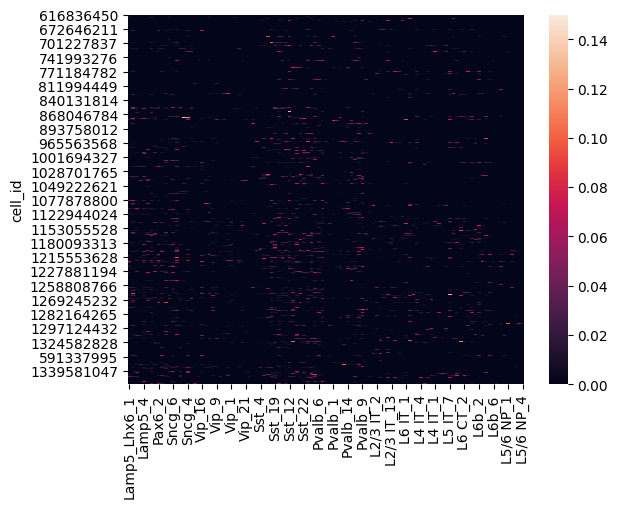

In [11]:
sns.heatmap(difference_df)

In [12]:
tx_mapping_top_four_df_norm = tx_mapping_top_four_df.div(tx_mapping_top_four_df.sum(axis=1), axis=0).fillna(0)


<Axes: ylabel='cell_id'>

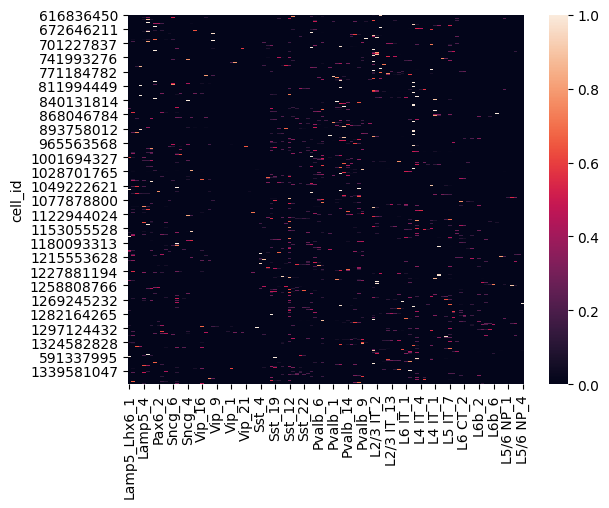

In [13]:
sns.heatmap(tx_mapping_top_four_df_norm)

In [16]:
tx_mapping_top_four_df_norm.sum(axis=1)

cell_id
616836450     1.0
616840597     1.0
616858807     1.0
636982263     1.0
636986380     1.0
             ... 
1371191464    1.0
1371195226    1.0
1371210352    1.0
1371179407    1.0
1371210977    1.0
Length: 7444, dtype: float64

In [17]:
tx_mapping_top_four_df_norm.to_csv(r'\\allen\programs\celltypes\workgroups\mousecelltypes\SarahWB\datasets\human_exc\analysis\20240911_seaad\MET_typing\config_tree_top_four\tx_mapping_file.csv')